# Harmonogramowanie w zrobotyzowanej komórce: zadanie typu job-shop

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_4.ipynb)

W tym laboratorium planujemy pracę niewielkiej zautomatyzowanej komórki produkcyjnej. Przykład jest konkretny, a model odpowiada klasycznemu problemowi **harmonogramowania typu job-shop**.

Wybieramy czasy rozpoczęcia operacji tak, aby:

1. każdy zestaw przechodził przez wymaganą sekwencję stanowisk,
2. żadne stanowisko nie obsługiwało dwóch zestawów jednocześnie,
3. wszystkie zestawy były gotowe możliwie najwcześniej.

**Czas zakończenia wszystkich zadań** to *makespan*, zwykle oznaczany jako $C_{max}$.

## Pytania, które zbadamy

1. Jak zapisać opis komórki produkcyjnej jako zadania, stanowiska, operacje i czasy ich trwania?
2. Dlaczego potrzebujemy zmiennych binarnych, gdy dwie operacje konkurują o to samo stanowisko?
3. Jak zbudować niewielki mieszany model liniowy z całkowitoliczbowymi zmiennymi w PuLP?
4. Jak sprawdzić obliczony harmonogram przed zaufaniem wykresowi?
5. Jak odczytać produkcyjny wykres Gantta?

## Scenariusz: ostatnie minuty przed pokazem

Laboratorium robotyki przygotowuje cztery zestawy demonstracyjne przed przybyciem gości. Każdy zestaw musi odwiedzić trzy zautomatyzowane stanowiska, lecz kolejność zależy od zestawu.

Stanowiska mają w danych stałe angielskie nazwy:

- **Laser cutter** — wycinarka laserowa: wycina lub przycina części.
- **Robot arm** — ramię robota: montuje części.
- **Vision test** — kontrola wizyjna: sprawdza zestaw za pomocą kamery.

Nazwy zadań również pozostają kluczami danych: **Frame kit** to zestaw ramy, **Sensor mast** — maszt czujnika, **Gripper jaw** — szczęka chwytaka, a **Battery tray** — uchwyt akumulatora. Używaj tych samych kluczy przy odczycie tabel i zmianach danych.

Stanowisko może obsługiwać tylko jeden zestaw naraz. Zestaw może czekać między stanowiskami, ale nie może pominąć operacji ani zmienić własnej kolejności.

## Ilustracja komórki robotycznej

![Harmonogramowanie w zrobotyzowanej komórce](https://raw.githubusercontent.com/AdoHaha/automation_robotics_lab/refs/heads/master/job_illustration.png)

Ilustracja przedstawia współdzieloną komórkę: każdy zestaw ma ustaloną trasę, stanowiska obsługują po jednym zestawie, a oczekujące zestawy znajdują się w buforze.

In [11]:
# Sprawdź dostępność solvera również w nowej sesji Colab.
try:
    import pulp
except ModuleNotFoundError:
    %pip install "pulp>=3.3,<4" pandas matplotlib
    import pulp

import pandas as pd

# Dane głównego ćwiczenia.
# Każde zadanie to trasa: (station, processing_time_in_minutes), czyli stanowisko i czas w minutach.
jobs = {
    "Frame kit": [
        ("Laser cutter", 3),
        ("Robot arm", 4),
        ("Vision test", 2),
    ],
    "Sensor mast": [
        ("Robot arm", 2),
        ("Laser cutter", 4),
        ("Vision test", 3),
    ],
    "Gripper jaw": [
        ("Laser cutter", 2),
        ("Vision test", 1),
        ("Robot arm", 3),
    ],
    "Battery tray": [
        ("Vision test", 2),
        ("Robot arm", 3),
        ("Laser cutter", 3),
    ],
}

# Zapisz krotki tras jako wiersze DataFrame, aby łatwo obejrzeć każdą operację.
operation_rows = []
for job, route in jobs.items():
    for operation, (station, duration) in enumerate(route, start=1):
        operation_rows.append({
            "job": job,
            "operation": operation,
            "station": station,
            "duration": duration,
        })

operations = pd.DataFrame(operation_rows)
operations


,job,operation,station,duration
0,Frame kit,1,Laser cutter,3
1,Frame kit,2,Robot arm,4
2,Frame kit,3,Vision test,2
3,Sensor mast,1,Robot arm,2
4,Sensor mast,2,Laser cutter,4
5,Sensor mast,3,Vision test,3
6,Gripper jaw,1,Laser cutter,2
7,Gripper jaw,2,Vision test,1
8,Gripper jaw,3,Robot arm,3
9,Battery tray,1,Vision test,2


In [12]:
import sys
# Odinstalowanie i ponowna czysta instalacja pulp w celu wyeliminowania konfliktów bibliotek
!{sys.executable} -m pip uninstall -y pulp
!{sys.executable} -m pip install "pulp>=2.8,<3.0"

Found existing installation: PuLP 2.9.0
Uninstalling PuLP-2.9.0:
  Successfully uninstalled PuLP-2.9.0
  Using cached PuLP-2.9.0-py3-none-any.whl.metadata (5.4 kB)
Using cached PuLP-2.9.0-py3-none-any.whl (17.7 MB)


In [13]:
import pulp
import pandas as pd
print("Zainstalowana wersja PuLP:", pulp.__version__)

Zainstalowana wersja PuLP: 2.9.0


## Odczytaj dane jako operacje

Każdy wiersz opisuje jedną operację. Na przykład **Frame kit** najpierw korzysta z wycinarki laserowej przez 3 minuty, następnie z ramienia robota przez 4 minuty, a na końcu z kontroli wizyjnej przez 2 minuty.

Tabela jest wejściem modelu harmonogramowania. Solver wybierze tylko czasy rozpoczęcia i kolejność operacji konkurujących o dane stanowisko. Nazwy kolumn pozostają zgodne z kodem: `job` — zadanie, `operation` — numer operacji, `station` — stanowisko, `duration` — czas trwania.

## Diagram tras

Tabela pozwala odczytać dokładne dane. Poniższy diagram przedstawia te same informacje jako ścieżki przez komórkę.

`plot_job_routes(jobs)` przyjmuje słownik tras i zwraca parę obiektów Matplotlib `(fig, ax)`. Rozmieszcza elementy według zadań i kolejności operacji, rysuje dla każdej krotki prostokąt w kolorze stanowiska i łączy kolejne operacje. Po zmianie tras użyj funkcji ponownie, aby sprawdzić zgodność sekwencji z opisem. Położenie prostokąta nie oznacza zoptymalizowanego czasu rozpoczęcia.

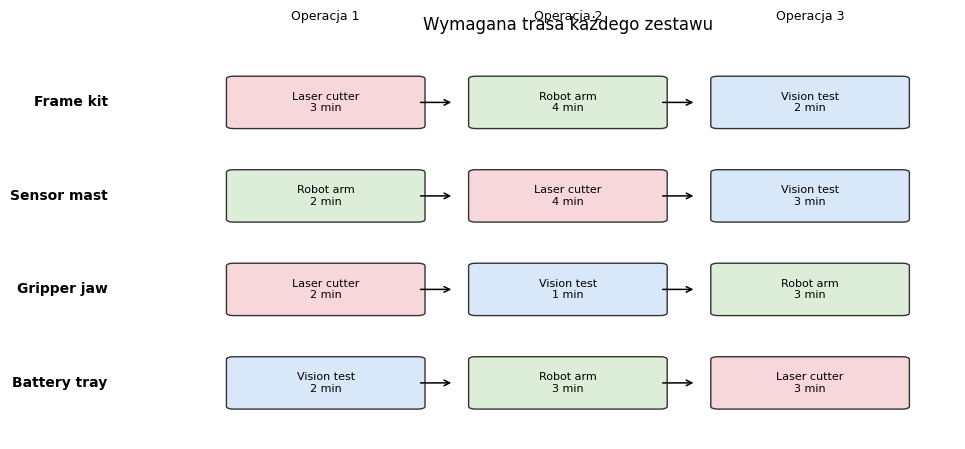

In [14]:
# Pokaż kolejność operacji prostokątami w kolorach stanowisk; to nie jest harmonogram czasowy.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def plot_job_routes(jobs):
    """Rysuje wymaganą trasę operacji każdego zadania, bez harmonogramowania.

    jobs przypisuje nazwom zadań uporządkowane krotki
    (station, processing_time_in_minutes). Pozycja x prostokąta oznacza
    kolejność operacji, nie czas rozpoczęcia; kolor oznacza stanowisko.
    Korzysta z globalnych plt i FancyBboxPatch. Tworzy figurę i zwraca
    (fig, ax) do wyświetlenia lub modyfikacji. Nie wymaga solvera."""
    station_colors = {
        "Laser cutter": "#F8D7DA",
        "Robot arm": "#DDEED8",
        "Vision test": "#D8E8F8",
    }

    # Współrzędne rozdzielają zadania pionowo, a etapy trasy poziomo.
    job_names = list(jobs)
    max_operations = max(len(route) for route in jobs.values())
    fig, ax = plt.subplots(figsize=(10, 0.9 * len(job_names) + 1.5))
    ax.set_xlim(0.4, max_operations + 0.6)
    ax.set_ylim(-0.6, len(job_names) - 0.4)
    ax.axis("off")

    # Narysuj prostokąty trasy i połącz je z kolejnymi wymaganymi operacjami.
    for y, job in enumerate(reversed(job_names)):
        ax.text(0.1, y, job, ha="right", va="center", fontsize=10, weight="bold")
        route = jobs[job]
        for operation, (station, duration) in enumerate(route, start=1):
            x = operation
            box = FancyBboxPatch(
                (x - 0.38, y - 0.25),
                0.76,
                0.5,
                boxstyle="round,pad=0.03",
                linewidth=1,
                edgecolor="#333333",
                facecolor=station_colors.get(station, "#EFEFEF"),
            )
            ax.add_patch(box)
            ax.text(x, y, f"{station}\n{duration} min", ha="center", va="center", fontsize=8)
            if operation < len(route):
                ax.annotate("", xy=(x + 0.53, y), xytext=(x + 0.38, y), arrowprops={"arrowstyle": "->", "lw": 1.1})

    for operation in range(1, max_operations + 1):
        ax.text(operation, len(job_names) - 0.15, f"Operacja {operation}", ha="center", va="bottom", fontsize=9)

    ax.set_title('Wymagana trasa każdego zestawu', pad=12)
    return fig, ax


plot_job_routes(jobs);

## Rozgrzewka: dwa zadania i dwa stanowiska

Najpierw rozwiąż ręcznie mały przykład.

- Zadanie A (`Job A`): `Station 1` przez 5 minut, następnie `Station 2` przez 6 minut.
- Zadanie B (`Job B`): `Station 2` przez 4 minuty, następnie `Station 1` przez 7 minut.

`Station 1` i `Station 2` oznaczają stanowiska 1 i 2; angielskie nazwy są kluczami danych.

Pytania:

1. Czy obie pierwsze operacje mogą rozpocząć się w chwili 0?
2. Co musi się wydarzyć, zanim zadanie A skorzysta ze stanowiska 2?
3. Co musi się wydarzyć, zanim zadanie B skorzysta ze stanowiska 1?
4. Narysuj ręcznie harmonogram. Optymalny czas zakończenia wszystkich zadań wynosi **12 minut**.

Na każdym stanowisku albo A poprzedza B, albo B poprzedza A. Tę decyzję „albo–albo” reprezentuje zmienna binarna.

In [15]:
# Zapisz przykład dwóch zadań i przekształć go w czytelną tabelę operacji.
warmup_jobs = {
    "Job A": [
        ("Station 1", 5),
        ("Station 2", 6),
    ],
    "Job B": [
        ("Station 2", 4),
        ("Station 1", 7),
    ],
}

warmup_rows = []
for job, route in warmup_jobs.items():
    for operation, (station, duration) in enumerate(route, start=1):
        warmup_rows.append({
            "job": job,
            "operation": operation,
            "station": station,
            "duration": duration,
        })

pd.DataFrame(warmup_rows)


,job,operation,station,duration
0,Job A,1,Station 1,5
1,Job A,2,Station 2,6
2,Job B,1,Station 2,4
3,Job B,2,Station 1,7


## Idea modelu

Dla każdej operacji tworzymy zmienną czasu rozpoczęcia:

$$s_{j,k} \ge 0$$

gdzie $j$ oznacza zadanie, a $k$ — numer operacji w tym zadaniu.

Model zawiera trzy grupy ograniczeń.

### 1. Kolejność operacji w zadaniu

Jeśli operacja 2 następuje po operacji 1, nie może rozpocząć się przed zakończeniem operacji 1:

$$s_{j,2} \ge s_{j,1} + p_{j,1}$$

### 2. Brak nakładania się operacji na jednym stanowisku

Jeśli operacje `a` i `b` wymagają tego samego stanowiska, jedna musi poprzedzać drugą. Wprowadzamy zmienną binarną $y_{a,b}$.

Dla $y_{a,b}=1$ operacja `a` poprzedza `b`; dla $y_{a,b}=0$ operacja `b` poprzedza `a`.

Dwa ograniczenia typu duże M (Big-M) mają postać:

$$s_b \ge s_a + p_a - M(1-y_{a,b})$$

$$s_a \ge s_b + p_b - My_{a,b}$$

Składnik z dużym M działa jak przełącznik. Po wybraniu kolejności jedno ograniczenie jest aktywne i zapobiega nakładaniu się operacji. Drugie zawiera duże odejmowanie, więc przestaje ograniczać harmonogram. $M$ musi być dostatecznie duże, aby wyłączyć nieaktywny warunek, lecz nie przesadnie duże. Tutaj przyjmujemy sumę czasów wszystkich operacji: to bezpieczny horyzont tego podstawowego modelu, ponieważ nawet wykonywanie operacji pojedynczo zakończyłoby się do tej chwili. Jeśli dodasz czasy dostępności zadań, okna konserwacji lub inne warunki wymuszające przestoje, zwiększ horyzont, aby duże M nadal było wystarczające.

### 3. Czas zakończenia wszystkich zadań

Czas zakończenia wszystkich zadań musi być nie mniejszy od czasu zakończenia ostatniej operacji każdego zadania:

$$C_{max} \ge s_{j,last} + p_{j,last}$$

Funkcja celu:

$$\min C_{max}$$

### Solver wielokrotnego użytku: słownik tras → tabela harmonogramu

`solve_jobshop(jobs, msg=False, horizon=None)` przyjmuje uporządkowany słownik tras, tworzy zmienne czasu i kolejności, dodaje ograniczenia tras, rozłączności oraz czasu zakończenia, rozwiązuje model i zapisuje optymalne czasy w DataFrame. Zwraca `(makespan, schedule, model)`, więc rozgrzewka i główny przykład korzystają z tej samej implementacji. Klucze `(job, operation_index)` identyfikują operacje: wewnętrzne indeksy zaczynają się od zera, a numery w tabeli — od jednego. Pomocnicze funkcje `_safe_name` i `_operation_name` tworzą czytelne nazwy solvera z etykiet i krotek. Gdy solver nie znajdzie optimum, funkcja zgłasza błąd przed odczytaniem harmonogramu.

In [16]:
# Funkcje nazw i solver wielokrotnego użytku łączą dane tras z modelem matematycznym.
from itertools import combinations
import re

import pulp


def _safe_name(text):
    """Zwraca nazwę zadania, stanowiska lub innego obiektu bezpieczną dla solvera.

    Zamienia text na str; grupy znaków spoza liter łacińskich, cyfr i
    podkreślenia zastępuje jednym podkreśleniem, a skrajne podkreślenia usuwa.
    Korzysta z globalnego re. Nie ma jednostek, nie uruchamia solvera ani
    niczego nie wyświetla. Służy do nazywania zmiennych i ograniczeń."""
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(text)).strip("_")


def _operation_name(operation):
    """Zwraca nazwę solvera dla krotki (job_name, zero_based_index).

    Używa _safe_name dla zadania i zapisuje indeks operacji od 1, zgodnie
    z etykietami tabeli harmonogramu. Zwraca napis bez jednostek fizycznych,
    niczego nie wyświetla. Służy do nazywania początków, ograniczeń tras
    i binarnych zmiennych kolejności."""
    job, index = operation
    return f"{_safe_name(job)}_op{index + 1}"


def solve_jobshop(jobs, msg=False, horizon=None):
    """Rozwiązuje niewielki model job-shop bez przerywania operacji, używając CBC.

    jobs przypisuje zadaniom uporządkowane krotki
    (station, processing_time_minutes). msg=False wyłącza log solvera.
    horizon=None przyjmuje sumę czasów operacji jako duże M; jawny horizon
    też ma jednostkę minut i musi obejmować ewentualne dodatkowe przestoje.
    Korzysta z globalnych pulp/pd, combinations, _safe_name i _operation_name.

    Zwraca (makespan_minutes, schedule, model). schedule jest DataFrame
    z kolumnami job, operation (numer od 1), station, start, duration, finish;
    trzy kolumny czasu są w minutach. model to rozwiązany problem PuLP.
    Zgłasza RuntimeError, gdy status nie jest Optimal lub brakuje czasów
    rozpoczęcia. Nie wyświetla ani niezależnie nie sprawdza harmonogramu;
    w tym celu wywołaj validate_schedule."""
    model = pulp.LpProblem("Robot_Cell_Job_Shop", pulp.LpMinimize)

    # Klucze (job, indeks operacji od zera) łączą początki, stanowiska i czasy trwania.
    operations = [
        (job, operation_index)
        for job, route in jobs.items()
        for operation_index in range(len(route))
    ]
    station_of = {
        (job, operation_index): jobs[job][operation_index][0]
        for job, operation_index in operations
    }
    duration = {
        (job, operation_index): jobs[job][operation_index][1]
        for job, operation_index in operations
    }
    if horizon is None:
        horizon = sum(duration[operation] for operation in operations)

    # Utwórz ciągłe zmienne czasu; binarne zmienne kolejności dodamy dla współdzielonych stanowisk.
    start = {
        operation: pulp.LpVariable(
            f"start___{_operation_name(operation)}",
            lowBound=0,
            cat="Continuous",
        )
        for operation in operations
    }
    cmax = pulp.LpVariable("Cmax", lowBound=0, cat="Continuous")

    model += cmax, "minimize_makespan"

    # Ograniczenia trasy: operacje zadania zachowują wymaganą kolejność.
    for job, route in jobs.items():
        for operation_index in range(len(route) - 1):
            current_operation = (job, operation_index)
            next_operation = (job, operation_index + 1)
            model += (
                start[next_operation] >= start[current_operation] + duration[current_operation],
                f"route__{_operation_name(current_operation)}__before__{_operation_name(next_operation)}",
            )

    # Ograniczenia rozłączności: operacje jednego stanowiska nie mogą nakładać się w czasie.
    stations = sorted({station for route in jobs.values() for station, _ in route})
    for station in stations:
        station_operations = [operation for operation in operations if station_of[operation] == station]
        for first_operation, second_operation in combinations(station_operations, 2):
            order = pulp.LpVariable(
                f"order__{_safe_name(station)}__{_operation_name(first_operation)}__before__{_operation_name(second_operation)}",
                cat="Binary",
            )
            model += (
                start[second_operation]
                >= start[first_operation] + duration[first_operation] - horizon * (1 - order),
                f"no_overlap__{_safe_name(station)}__{_operation_name(first_operation)}__before__{_operation_name(second_operation)}",
            )
            model += (
                start[first_operation]
                >= start[second_operation] + duration[second_operation] - horizon * order,
                f"no_overlap__{_safe_name(station)}__{_operation_name(second_operation)}__before__{_operation_name(first_operation)}",
            )

    # Cmax musi przypadać po zakończeniu ostatniej operacji każdego zadania.
    for job, route in jobs.items():
        last_operation = (job, len(route) - 1)
        model += (
            cmax >= start[last_operation] + duration[last_operation],
            f"makespan_after__{_safe_name(job)}",
        )

    # Rozwiąż model i sprawdź status przed odczytaniem zmiennych do tabeli harmonogramu.
    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        raise RuntimeError(
            f"Status solvera: {status}; oczekiwano Optimal. "
            'Sprawdź wykonalność tras i ograniczeń rozłączności. '
            'Jeśli dodano czasy dostępności lub okna konserwacji, sprawdź też, czy horyzont/duże M jest wystarczające.'
        )

    # Zapisz optymalne początki w tabeli posortowanej według stanowiska i czasu.
    rows = []
    for job, route in jobs.items():
        for operation_index, (station, processing_time) in enumerate(route):
            operation = (job, operation_index)
            start_time = pulp.value(start[operation])
            if start_time is None:
                raise RuntimeError(
                    f"Brak czasu rozpoczęcia dla {job}, operacja {operation_index + 1}. "
                    'Sprawdź status solvera i ograniczenia modelu.'
                )
            rows.append({
                "job": job,
                "operation": operation_index + 1,
                "station": station,
                "start": start_time,
                "duration": processing_time,
                "finish": start_time + processing_time,
            })

    schedule = (
        pd.DataFrame(rows)
        .sort_values(["station", "start", "job"])
        .reset_index(drop=True)
    )
    return pulp.value(cmax), schedule, model

In [17]:
# Najpierw użyj solvera dla przykładu sprawdzonego ręcznie, potem dla pełnej komórki.
warmup_makespan, warmup_schedule, warmup_model = solve_jobshop(warmup_jobs)
print(f"Optymalny czas zakończenia wszystkich zadań rozgrzewki: {warmup_makespan:.0f} minut")
print('Oczekiwana wartość dla pierwotnych danych rozgrzewki: 12 minut')
warmup_schedule


Optymalny czas zakończenia wszystkich zadań rozgrzewki: 12 minut
Oczekiwana wartość dla pierwotnych danych rozgrzewki: 12 minut


,job,operation,station,start,duration,finish
0,Job A,1,Station 1,0.0,5,5.0
1,Job B,2,Station 1,5.0,7,12.0
2,Job B,1,Station 2,0.0,4,4.0
3,Job A,2,Station 2,5.0,6,11.0


In [18]:
# Rozwiąż główny przykład tą samą funkcją i obejrzyj harmonogram w minutach.
makespan, schedule, model = solve_jobshop(jobs)
print(f"Optymalny czas zakończenia wszystkich zadań komórki: {makespan:.0f} minut")
print('Oczekiwana wartość dla pierwotnych danych komórki: 13 minut')
schedule


Optymalny czas zakończenia wszystkich zadań komórki: 13 minut
Oczekiwana wartość dla pierwotnych danych komórki: 13 minut


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Sensor mast,2,Laser cutter,3.0,4,7.0
2,Gripper jaw,1,Laser cutter,7.0,2,9.0
3,Battery tray,3,Laser cutter,10.0,3,13.0
4,Sensor mast,1,Robot arm,0.0,2,2.0
5,Frame kit,2,Robot arm,3.0,4,7.0
6,Battery tray,2,Robot arm,7.0,3,10.0
7,Gripper jaw,3,Robot arm,10.0,3,13.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Frame kit,3,Vision test,7.0,2,9.0


## Sprawdź harmonogram przed narysowaniem wykresu

Wykres Gantta ułatwia oglądanie harmonogramu, ale najpierw automatycznie sprawdź reguły.

Poprawny harmonogram spełnia dwa warunki:

1. każde zadanie zachowuje kolejność swojej trasy,
2. operacje na tym samym stanowisku nie nakładają się w czasie.

`validate_schedule(jobs, schedule, tolerance=1e-7)` przyjmuje pierwotne trasy i tabelę harmonogramu. Indeksuje wiersze krotkami operacji, sprawdza kolejność, a następnie grupuje i sortuje operacje według stanowisk, aby porównać sąsiednie przedziały. Zwraca komunikat potwierdzający poprawność albo zgłasza błąd asercji przy naruszeniu reguły. Uruchamiaj ją po każdym rozwiązaniu scenariusza; tolerancja to niewielka liczba minut uwzględniająca błędy numeryczne solvera.

In [19]:
# Sprawdź reguły harmonogramu niezależnie od modelu optymalizacji.
def validate_schedule(jobs, schedule, tolerance=1e-7):
    """Sprawdza kolejność tras i rozłączność operacji w rozwiązanym harmonogramie.

    jobs to uporządkowany słownik tras użyty w modelu. schedule jest tabelą
    z solve_jobshop, z numerami operacji od 1 i start/finish w minutach.
    tolerance=1e-7 minut pomija szum numeryczny. Zakłada obecność wszystkich
    operacji modelu w tabeli. Zwraca "Harmonogram jest poprawny.", jeśli
    oba warunki są spełnione; w przeciwnym razie zgłasza AssertionError.
    Nie uruchamia solvera ani niczego nie wyświetla. Wywołuj po każdym
    ponownym rozwiązaniu, przed rysowaniem wykresu."""
    # Indeksuj wiersze krotkami, aby łatwo porównać kolejne operacje trasy.
    indexed = {
        (row.job, int(row.operation) - 1): row
        for row in schedule.itertuples(index=False)
    }

    # Następnik nie może rozpocząć się przed zakończeniem poprzednika.
    for job, route in jobs.items():
        for operation_index in range(len(route) - 1):
            current_operation = indexed[(job, operation_index)]
            next_operation = indexed[(job, operation_index + 1)]
            if next_operation.start + tolerance < current_operation.finish:
                raise AssertionError(
                    f"Naruszenie trasy zadania {job}: operacja {operation_index + 2} "
                    f"zaczyna się przed zakończeniem operacji {operation_index + 1}."
                )

    # Posortuj operacje stanowiska w czasie i sprawdź nakładanie sąsiednich przedziałów.
    for station, station_schedule in schedule.groupby("station"):
        ordered = station_schedule.sort_values("start")
        previous_operation = None
        for operation in ordered.itertuples(index=False):
            if (
                previous_operation is not None
                and operation.start + tolerance < previous_operation.finish
            ):
                raise AssertionError(
                    f"Nakładanie operacji na {station}: {previous_operation.job} i {operation.job}."
                )
            previous_operation = operation

    return 'Harmonogram jest poprawny.'


validate_schedule(warmup_jobs, warmup_schedule), validate_schedule(jobs, schedule)

('Harmonogram jest poprawny.', 'Harmonogram jest poprawny.')

## Funkcja wykresu Gantta: tabela → oś czasu stanowisk

`plot_gantt(schedule, title=...)` przyjmuje sprawdzoną tabelę harmonogramu i zwraca `(fig, ax)`. Przypisuje stanowiskom wiersze, a zadaniom kolory; rysuje operacje od ich czasów rozpoczęcia, z szerokością równą czasowi trwania, a następnie dodaje etykiety minut, stanowisk i legendę zadań. Po zmianie tras lub czasów użyj jej ponownie. Funkcja pokazuje podane wartości — nie rozwiązuje modelu ani nie sprawdza harmonogramu.

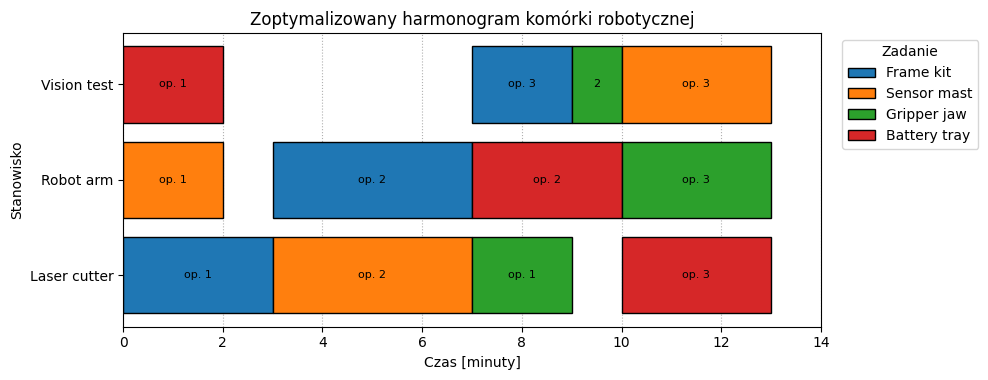

In [20]:
# Narysuj sprawdzony harmonogram jako paski na osiach czasu stanowisk.
import matplotlib.pyplot as plt


def plot_gantt(schedule, title='Zoptymalizowany harmonogram komórki robotycznej'):
    """Tworzy wykres Gantta stanowisko–czas z tabeli rozwiązanego harmonogramu.

    schedule ma kolumny job, operation, station, start, duration, finish;
    wszystkie czasy są w minutach. title domyślnie opisuje zoptymalizowany
    harmonogram komórki. Korzysta z globalnego plt; kolor identyfikuje
    zadanie, a wiersz — stanowisko. Zwraca (fig, ax) do wyświetlenia lub
    modyfikacji. Rysuje podane dane bez rozwiązywania modelu i sprawdzania
    reguł; najpierw wywołaj validate_schedule."""
    # Przypisz stanowiskom pozycje y, a zadaniom spójne kolory.
    stations = list(schedule["station"].drop_duplicates())
    jobs_in_schedule = list(schedule["job"].drop_duplicates())
    y_position = {station: index for index, station in enumerate(stations)}
    color_map = {
        job: plt.get_cmap("tab10")(index % 10)
        for index, job in enumerate(jobs_in_schedule)
    }

    fig_height = max(3.5, 0.8 * len(stations) + 1.5)
    fig, ax = plt.subplots(figsize=(10, fig_height))
    labelled_jobs = set()

    # Wiersze tabeli wyznaczają początek i szerokość pasków oraz jedną etykietę legendy na zadanie.
    for row in schedule.itertuples(index=False):
        y = y_position[row.station]
        label = row.job if row.job not in labelled_jobs else None
        labelled_jobs.add(row.job)

        ax.barh(
            y,
            row.duration,
            left=row.start,
            color=color_map[row.job],
            edgecolor="black",
            label=label,
        )
        operation_label = f"op. {int(row.operation)}" if row.duration >= 1.8 else str(int(row.operation))
        ax.text(
            row.start + row.duration / 2,
            y,
            operation_label,
            ha="center",
            va="center",
            fontsize=8,
        )

    # Podpisz minuty i stanowiska oraz pozostaw miejsce na legendę zadań.
    ax.set_yticks(list(y_position.values()))
    ax.set_yticklabels(list(y_position.keys()))
    ax.set_xlabel('Czas [minuty]')
    ax.set_ylabel('Stanowisko')
    ax.set_title(title)
    ax.set_xlim(0, schedule["finish"].max() + 1)
    ax.grid(axis="x", linestyle=":")
    ax.set_axisbelow(True)
    ax.legend(title='Zadanie', bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    return fig, ax


plot_gantt(schedule);

## Zadania do wykonania

### Zadanie 1: wskaż elementy optymalizacji

Uzupełnij:

- Zadania: `__________`
- Stanowiska: `__________`
- Zmienne decyzyjne: `__________`
- Funkcja celu: `__________`
- Dwie główne rodziny ograniczeń: `__________`

### Zadanie 2: zmień dane

Ramię robota otrzymuje szybszy chwytak. Każda operacja **Robot arm** trwa o 1 minutę krócej, ale nie mniej niż 1 minutę. Rozwiąż model ponownie. O ile poprawia się czas zakończenia wszystkich zadań?

### Zadanie 3: analiza wąskich gardeł

Na podstawie wykresu Gantta odpowiedz:

- Które stanowisko pracuje najdłużej?
- Które stanowisko ma najwięcej czasu bezczynności?
- Które zadanie kończy się jako ostatnie?
- Czy ostatnie zadanie musi być wąskim gardłem? Wyjaśnij.

### Zadanie 4: dodaj okno konserwacji

Stanowisko kontroli wizyjnej jest niedostępne od chwili 4 do chwili 6. Rozszerz model tak, aby żadna operacja na tym stanowisku nie nakładała się na ten przedział.

Wskazówka: to kolejna decyzja „albo–albo”. Każda operacja kontroli wizyjnej musi zakończyć się przed minutą 4 albo rozpocząć po minucie 6.

### Wyzwanie: terminy realizacji

Załóż, że gościom najbardziej zależy na `Frame kit`, który ma być gotowy w minucie 10. Dodaj zmienną spóźnienia.

Czas zakończenia $C_j$ określa, kiedy zadanie $j$ jest gotowe. Termin $d_j$ określa, kiedy powinno być gotowe. Spóźnienie to opóźnienie względem terminu:

$$T_j \ge C_j - d_j$$

Dodaj również $T_j \ge 0$, ponieważ wcześniejsze zakończenie ma dawać zerowe spóźnienie, a nie ujemną karę. Jeśli `Frame kit` kończy się w minucie 13, a termin wynosi 10, to $T_j=3$.

Następnie rozwiąż jeden z wariantów:

- najpierw minimalizuj czas zakończenia wszystkich zadań, a następnie spóźnienie,
- albo minimalizuj `makespan + 0.5 * total_tardiness`.

### Zadanie 1: Elementy optymalizacji

- **Zadania**: Zestawy demonstracyjne: `Frame kit`, `Sensor mast`, `Gripper jaw`, `Battery tray`.
- **Stanowiska**: Maszyny współdzielone: `Laser cutter` (wycinarka), `Robot arm` (ramię robota), `Vision test` (kontrola wizyjna).
- **Zmienne decyzyjne**:
  - Ciągłe zmienne $s_{j,k} \ge 0$ oznaczające czas rozpoczęcia operacji $k$ dla zadania $j$.
  - Binarne zmienne $y_{a,b}$ określające kolejność wykonania zadań na tym samym stanowisku.
  - Ciągła zmienna $C_{max}$ reprezentująca czas zakończenia wszystkich zadań (makespan).
- **Funkcja celu**: Minimalizacja całkowitego czasu zakończenia: $\min C_{max}$.
- **Dwie główne rodziny ograniczeń**:
  1. Ograniczenia sekwencji technologicznej (trasy) zadania: operacja kolejna nie może wystartować przed zakończeniem poprzedniej.
  2. Ograniczenia rozłączności (brak nakładania się operacji na tym samym stanowisku) modelowane metodą Big-M.

### Rozgrzewka: Analiza ręczna i pytania

- **Czy obie pierwsze operacje mogą rozpocząć się w chwili 0?**
  - Tak. Pierwsza operacja `Job A` odbywa się na `Station 1`, a pierwsza operacja `Job B` na `Station 2`. Ponieważ są to dwa różne stanowiska, obie operacje mogą wystartować dokładnie w chwili 0.
- **Co musi się wydarzyć, zanim zadanie A skorzysta ze stanowiska 2?**
  - Zadanie A musi najpierw zakończyć swoją pierwszą operację na `Station 1` (co trwa 5 minut). Ponadto `Station 2` musi być wolna (zadanie B musi zakończyć swoją pierwszą operację trwającą 4 minuty).
- **Co musi się wydarzyć, zanim zadanie B skorzysta ze stanowiska 1?**
  - Zadanie B musi zakończyć swoją pierwszą operację na `Station 2` (4 minuty) oraz `Station 1` musi zakończyć pracę nad pierwszą operacją zadania A (5 minut).
- **Ręczne uszeregowanie (makespan = 12 minut)**:
  - `Station 1`: Job A (0-5), Job B (5-12)
  - `Station 2`: Job B (0-4), Job A (5-11)

Ręcznie wyznaczony harmonogram rozgrzewki:


,job,operation,station,start,duration,finish
0,Job A,1,Station 1,0.0,5,5.0
1,Job B,2,Station 1,5.0,7,12.0
2,Job B,1,Station 2,0.0,4,4.0
3,Job A,2,Station 2,5.0,6,11.0


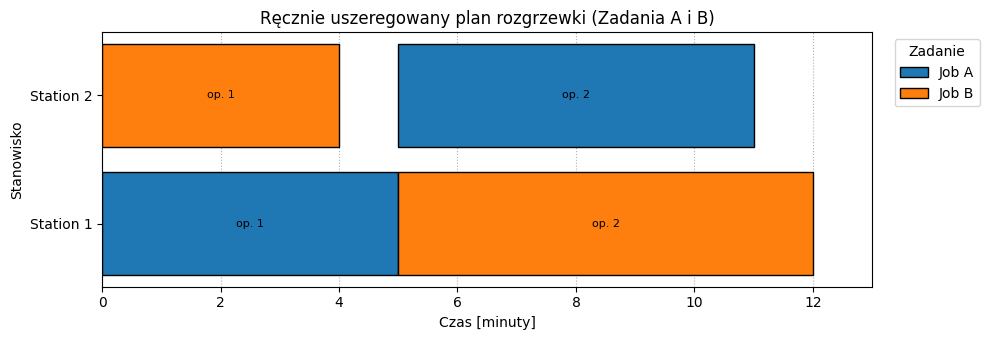

In [24]:
# Ręcznie ułożony harmonogram z rozgrzewki (makespan = 12 minut)
import pandas as pd

warmup_manual_rows = [
    # Station 1
    {"job": "Job A", "operation": 1, "station": "Station 1", "start": 0.0, "duration": 5, "finish": 5.0},
    {"job": "Job B", "operation": 2, "station": "Station 1", "start": 5.0, "duration": 7, "finish": 12.0},
    # Station 2
    {"job": "Job B", "operation": 1, "station": "Station 2", "start": 0.0, "duration": 4, "finish": 4.0},
    {"job": "Job A", "operation": 2, "station": "Station 2", "start": 5.0, "duration": 6, "finish": 11.0}
]

warmup_manual_schedule = pd.DataFrame(warmup_manual_rows)
print("Ręcznie wyznaczony harmonogram rozgrzewki:")
display(warmup_manual_schedule)

# Wizualizacja ręcznego harmonogramu przy użyciu dostosowanej funkcji plot_gantt
plot_gantt(warmup_manual_schedule, title='Ręcznie uszeregowany plan rozgrzewki (Zadania A i B)');

### Zadanie 2: Zmiana danych (Szybsze ramię robota)

Skracamy czas trwania operacji na stanowisku **Robot arm** o 1 minutę (ale nie mniej niż 1 minuta).

Oryginalny makespan: 13 minut
Nowy makespan: 12 minut
Czas poprawił się o: 1 min


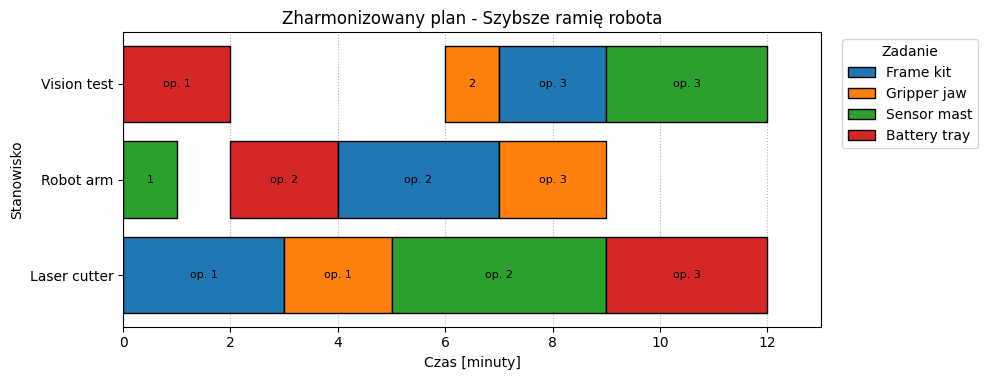

In [21]:
modified_jobs = {}
for j, route in jobs.items():
    new_route = []
    for station, duration in route:
        if station == "Robot arm":
            new_duration = max(1, duration - 1)
        else:
            new_duration = duration
        new_route.append((station, new_duration))
    modified_jobs[j] = new_route

mod_makespan, mod_schedule, mod_model = solve_jobshop(modified_jobs)
print(f"Oryginalny makespan: {makespan:.0f} minut")
print(f"Nowy makespan: {mod_makespan:.0f} minut")
print(f"Czas poprawił się o: {makespan - mod_makespan:.0f} min")

validate_schedule(modified_jobs, mod_schedule)
plot_gantt(mod_schedule, title='Zharmonizowany plan - Szybsze ramię robota');

### Zadanie 3: Analiza wąskich gardeł

- **Które stanowisko pracuje najdłużej?**
  - **Laser cutter** (pracuje łącznie 12 minut z przerwą 9-10).
- **Które stanowisko ma najwięcej czasu bezczynności?**
  - **Vision test** (pracuje tylko 8 minut, stoi bezczynnie przez pierwsze 7 minut z wyjątkiem bloku 0-2).
- **Które zadanie kończy się jako ostatnie?**
  - **Sensor mast**, **Gripper jaw** oraz **Battery tray** kończą się równolegle w minucie 13.
- **Czy ostatnie zadanie musi być wąskim gardłem? Wyjaśnij.**
  - Nie. Ostatnie kończące się zadanie nie musi być wąskim gardłem. Wąskim gardłem jest zasób (stanowisko o ograniczonej przepustowości, np. Laser cutter), który blokuje przepływ pracy w całym systemie.

### Zadanie 4: Dodanie okna konserwacji na "Vision test" [4, 6]

Optymalny makespan z przerwą konserwacyjną: 13 minut


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Gripper jaw,1,Laser cutter,3.0,2,5.0
2,Sensor mast,2,Laser cutter,5.0,4,9.0
3,Battery tray,3,Laser cutter,10.0,3,13.0
4,Sensor mast,1,Robot arm,0.0,2,2.0
5,Frame kit,2,Robot arm,3.0,4,7.0
6,Battery tray,2,Robot arm,7.0,3,10.0
7,Gripper jaw,3,Robot arm,10.0,3,13.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Gripper jaw,2,Vision test,6.0,1,7.0


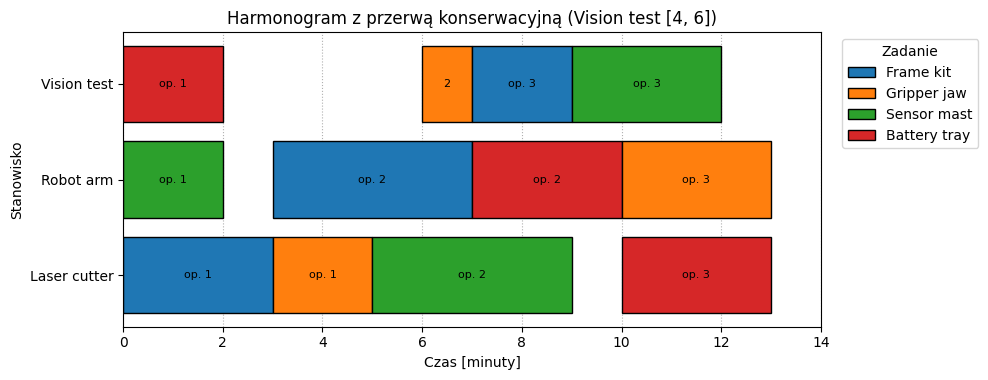

In [22]:
def solve_jobshop_with_maintenance(jobs, maintenance_station, m_start, m_finish):
    model = pulp.LpProblem("JobShop_Maintenance", pulp.LpMinimize)

    operations = [(j, idx) for j, r in jobs.items() for idx in range(len(r))]
    station_of = {op: jobs[op[0]][op[1]][0] for op in operations}
    duration = {op: jobs[op[0]][op[1]][1] for op in operations}

    # Horyzont uwzględnia przerwę konserwacyjną
    horizon = sum(duration[op] for op in operations) + (m_finish - m_start)

    start = {
        op: pulp.LpVariable(f"start___{_operation_name(op)}", lowBound=0, cat="Continuous")
        for op in operations
    }
    cmax = pulp.LpVariable("Cmax", lowBound=0, cat="Continuous")
    model += cmax, "minimize_makespan"

    # Trasy
    for job, route in jobs.items():
        for idx in range(len(route) - 1):
            model += start[(job, idx + 1)] >= start[(job, idx)] + duration[(job, idx)]

    # Rozłączność maszyn
    stations = sorted({s for r in jobs.values() for s, _ in r})
    for station in stations:
        station_ops = [op for op in operations if station_of[op] == station]
        for op1, op2 in combinations(station_ops, 2):
            order = pulp.LpVariable(f"order__{_safe_name(station)}__{_operation_name(op1)}__{_operation_name(op2)}", cat="Binary")
            model += start[op2] >= start[op1] + duration[op1] - horizon * (1 - order)
            model += start[op1] >= start[op2] + duration[op2] - horizon * order

    # Okno konserwacji na wybranym stanowisku (albo przed m_start, albo po m_finish)
    for op in operations:
        if station_of[op] == maintenance_station:
            m_var = pulp.LpVariable(f"maint__{_operation_name(op)}", cat="Binary")
            model += start[op] + duration[op] <= m_start + horizon * (1 - m_var)
            model += start[op] >= m_finish - horizon * m_var

    for job in jobs:
        last_op = (job, len(jobs[job]) - 1)
        model += cmax >= start[last_op] + duration[last_op]

    solver = pulp.PULP_CBC_CMD(msg=False)
    model.solve(solver)

    rows = []
    for op in operations:
        s_val = pulp.value(start[op])
        rows.append({
            "job": op[0], "operation": op[1] + 1, "station": station_of[op],
            "start": s_val, "duration": duration[op], "finish": s_val + duration[op]
        })

    schedule = pd.DataFrame(rows).sort_values(["station", "start"]).reset_index(drop=True)
    return pulp.value(cmax), schedule

maint_makespan, maint_schedule = solve_jobshop_with_maintenance(jobs, "Vision test", 4, 6)
print(f"Optymalny makespan z przerwą konserwacyjną: {maint_makespan:.0f} minut")
display(maint_schedule)
plot_gantt(maint_schedule, title='Harmonogram z przerwą konserwacyjną (Vision test [4, 6])');

### Wyzwanie: Minimalizacja Cmax + 0.5 * Suma Spóźnień

Całkowity czas zakończenia (makespan): 13 minut
Spóźnienie Frame kit: 0 minut


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Gripper jaw,1,Laser cutter,3.0,2,5.0
2,Sensor mast,2,Laser cutter,5.0,4,9.0
3,Battery tray,3,Laser cutter,10.0,3,13.0
4,Sensor mast,1,Robot arm,0.0,2,2.0
5,Frame kit,2,Robot arm,3.0,4,7.0
6,Battery tray,2,Robot arm,7.0,3,10.0
7,Gripper jaw,3,Robot arm,10.0,3,13.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Gripper jaw,2,Vision test,6.0,1,7.0


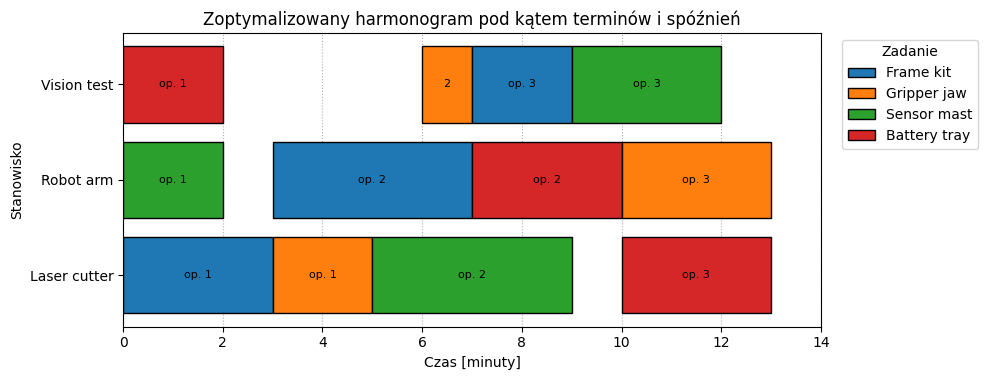

In [23]:
def solve_jobshop_with_tardiness(jobs, due_dates, weight_tardiness=0.5):
    model = pulp.LpProblem("JobShop_Tardiness", pulp.LpMinimize)

    operations = [(j, idx) for j, r in jobs.items() for idx in range(len(r))]
    station_of = {op: jobs[op[0]][op[1]][0] for op in operations}
    duration = {op: jobs[op[0]][op[1]][1] for op in operations}
    horizon = sum(duration[op] for op in operations)

    start = {
        op: pulp.LpVariable(f"start___{_operation_name(op)}", lowBound=0, cat="Continuous")
        for op in operations
    }
    cmax = pulp.LpVariable("Cmax", lowBound=0, cat="Continuous")
    tardiness = {
        job: pulp.LpVariable(f"tardiness__{_safe_name(job)}", lowBound=0, cat="Continuous")
        for job in jobs
    }

    # Funkcja celu
    model += cmax + weight_tardiness * pulp.lpSum(tardiness.values()), "minimize_combined_cost"

    # Trasy
    for job, route in jobs.items():
        for idx in range(len(route) - 1):
            model += start[(job, idx + 1)] >= start[(job, idx)] + duration[(job, idx)]

    # Rozłączność maszyn
    stations = sorted({s for r in jobs.values() for s, _ in r})
    for station in stations:
        station_ops = [op for op in operations if station_of[op] == station]
        for op1, op2 in combinations(station_ops, 2):
            order = pulp.LpVariable(f"order__{_safe_name(station)}__{_operation_name(op1)}__{_operation_name(op2)}", cat="Binary")
            model += start[op2] >= start[op1] + duration[op1] - horizon * (1 - order)
            model += start[op1] >= start[op2] + duration[op2] - horizon * order

    # Cmax i spóźnienia
    for job in jobs:
        last_op = (job, len(jobs[job]) - 1)
        finish_time = start[last_op] + duration[last_op]
        model += cmax >= finish_time
        if job in due_dates:
            model += tardiness[job] >= finish_time - due_dates[job]

    solver = pulp.PULP_CBC_CMD(msg=False)
    model.solve(solver)

    rows = []
    for op in operations:
        s_val = pulp.value(start[op])
        rows.append({
            "job": op[0], "operation": op[1] + 1, "station": station_of[op],
            "start": s_val, "duration": duration[op], "finish": s_val + duration[op]
        })

    schedule = pd.DataFrame(rows).sort_values(["station", "start"]).reset_index(drop=True)
    return pulp.value(cmax), {j: pulp.value(tardiness[j]) for j in jobs}, schedule

due_dates = {"Frame kit": 10}
c_val, t_vals, tardiness_schedule = solve_jobshop_with_tardiness(jobs, due_dates)
print(f"Całkowity czas zakończenia (makespan): {c_val:.0f} minut")
print(f"Spóźnienie Frame kit: {t_vals['Frame kit']:.0f} minut")
display(tardiness_schedule)
plot_gantt(tardiness_schedule, title='Zoptymalizowany harmonogram pod kątem terminów i spóźnień');